In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
from pathlib import Path
import re
from datetime import datetime
from typing import Optional, Union, Dict
from matplotlib.ticker import MultipleLocator
import matplotlib.ticker as ticker
from scipy.optimize import curve_fit

In [3]:
folder_path = "C:\\Users\\nicoe\\OneDrive - Imperial College London\\Documents\\A Univeristy\\Year 4\\Masters Project\\Results\\Experiments\\"

In [4]:
df_yig = pd.read_csv(f"{folder_path}VNA_FMR\\Results\\Data_analysis\\df_VNA_FMR_yig.csv", index_col=0)
print(df_yig.head())

                   0.001     0.005    0.0072    0.0093    0.0113    0.0129  \
Frequency (Hz)                                                               
300000.0        0.002159  0.002118  0.000525 -0.001314 -0.001715 -0.001265   
4299925.0       0.001329  0.001644  0.003549  0.002203  0.002471  0.001492   
8299850.0       0.002409  0.000661  0.000839  0.001421  0.002172  0.002235   
12299775.0      0.001270  0.000908  0.000819  0.000220  0.002574  0.000757   
16299700.0     -0.000047 -0.000408 -0.000646 -0.000055 -0.000826  0.000798   

                  0.0148    0.0168    0.0189    0.0208  ...    0.1819  \
Frequency (Hz)                                          ...             
300000.0       -0.000883 -0.000095 -0.000531  0.001654  ...  0.000018   
4299925.0       0.001973  0.002866  0.002357  0.002236  ...  0.001553   
8299850.0       0.003170  0.001933  0.000726  0.001789  ...  0.001808   
12299775.0      0.001038  0.000498  0.001193 -0.000357  ... -0.000452   
16299700.0     

average loss py: -0.0030579473011330895


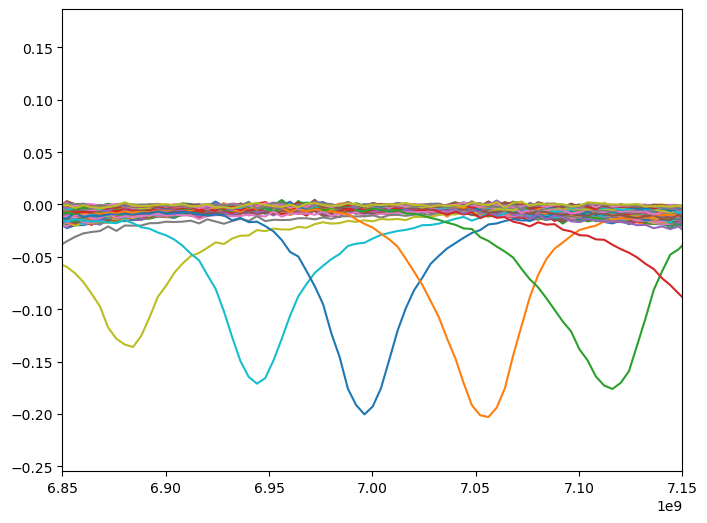

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
for col in df_yig.columns:
    ax.plot(df_yig.index, df_yig[col], label='YIG Sample')

ax.set_xlim(6.85e9, 7.15e9)
# print(f'average loss py: {df_yig[]}')

In [6]:
df_py = pd.read_csv(f"{folder_path}VNA_FMR\\Results\\Data_analysis\\df_VNA_FMR_Py.csv", index_col=0)
print(df_py.head())

                   0.001     0.003     0.005     0.007     0.009     0.011  \
Frequency (Hz)                                                               
300000.0        0.001518  0.001101  0.000138  0.000360  0.000451 -0.000038   
4549925.0       0.000777 -0.000120 -0.000162  0.000446 -0.000182  0.000142   
8799850.0      -0.000243  0.000610  0.000369  0.000808 -0.000394 -0.001450   
13049775.0     -0.000808  0.000629  0.000640  0.000558 -0.000151 -0.001555   
17299700.0     -0.001842  0.000345 -0.000725 -0.000672 -0.001127  0.000174   

                   0.013     0.015     0.017     0.019  ...     0.181  \
Frequency (Hz)                                          ...             
300000.0       -0.000601 -0.000963 -0.000812 -0.000230  ... -0.001153   
4549925.0      -0.000429  0.000312 -0.001227 -0.000734  ...  0.001737   
8799850.0       0.000100  0.000362  0.000852  0.000698  ...  0.001176   
13049775.0     -0.001409 -0.000053 -0.000427 -0.000570  ... -0.001643   
17299700.0     

average loss py: 0.024340904013722034


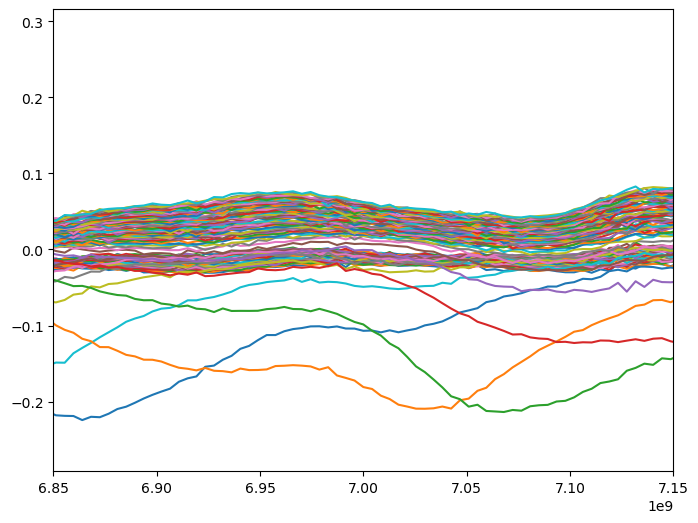

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
for col in df_py.columns:
    ax.plot(df_py.index, df_py[col], label='Py Sample')
    
ax.set_xlim(6.85e9, 7.15e9)

print(f'average loss py: {df_py.mean().mean()}')

In [49]:

K_B   = 1.380649e-23  # Boltzmann constant [J/K]
T_0   = 290.0         # IEEE reference temperature for noise figure [K]


# ── Temperatures ──────────────────────────────────────────────────────────────
# T_COLD = 9461                   # Cold terminal resistor temperature [K]
T_COLD = 77
T_ENV  = 290.0                  # Physical temperature of the lossy circuit [K]



In [50]:
# Create output dataframe

df = df_yig.copy()  # Use YIG data for noise PSD calculation (Py data is very noisy)
# df = df_py.copy()   # Use Py data for noise PSD calculation (YIG data is very noisy)


psd_df = pd.DataFrame(index=df.index)

for col in df.columns:

    # Convert S21 dB -> linear power gain
    G = 10**(df[col] / 10)

    # Output noise PSD (W/Hz)
    psd = K_B * (
        T_COLD * G +
        T_ENV * (1 - G)
    )

    psd_df[col] = psd

R = 50

noise_nv_sqrtHz_df = np.sqrt(psd_df * R) * 1e9  # Convert to nV/sqrt(Hz)

psd_dbm_hz_df = 10*np.log10(psd_df / 1e-3) #dbm/Hz

In [17]:
print(psd_df.head())

                       0.001         0.005        0.0072        0.0093  \
Frequency (Hz)                                                           
300000.0        1.061637e-21  1.061665e-21  1.062744e-21  1.063989e-21   
4299925.0       1.062199e-21  1.061986e-21  1.060696e-21  1.061608e-21   
8299850.0       1.061468e-21  1.062652e-21  1.062531e-21  1.062137e-21   
12299775.0      1.062240e-21  1.062485e-21  1.062545e-21  1.062950e-21   
16299700.0      1.063132e-21  1.063376e-21  1.063537e-21  1.063137e-21   

                      0.0113        0.0129        0.0148        0.0168  \
Frequency (Hz)                                                           
300000.0        1.064261e-21  1.063956e-21  1.063697e-21  1.063164e-21   
4299925.0       1.061426e-21  1.062089e-21  1.061763e-21  1.061158e-21   
8299850.0       1.061629e-21  1.061586e-21  1.060952e-21  1.061791e-21   
12299775.0      1.061356e-21  1.062587e-21  1.062396e-21  1.062762e-21   
16299700.0      1.063659e-21  1.06255

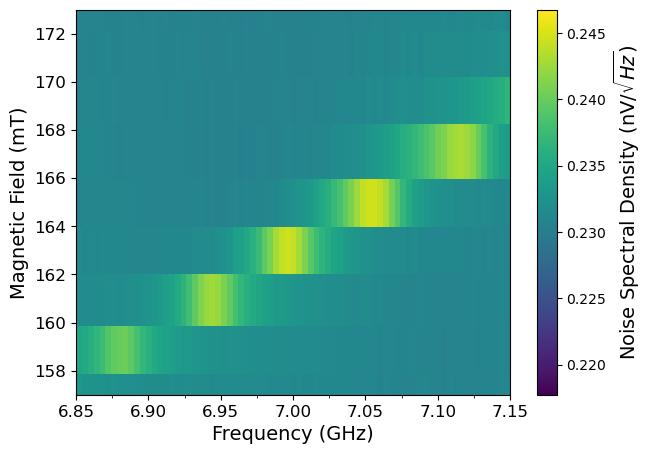

: 

In [ ]:
df = psd_df.copy()
df = noise_nv_sqrtHz_df.copy()

B = df.columns.values.astype(float)*1e3
F = df.index.values.astype(float)/1e9

# Meshgrid expects 2D grids
B_grid, F_grid = np.meshgrid(B, F)

Z = df.values  # shape: (freq, field)
fig, ax = plt.subplots(figsize=(7, 5))

mesh = ax.pcolormesh(F_grid, B_grid, Z, shading='auto', cmap="viridis", rasterized=True)

ax.set_ylabel("Magnetic Field (mT)", fontsize = 14)
ax.set_xlabel("Frequency (GHz)", fontsize = 14)
# plt.title("S21 Difference (Data - Calibration)")

ml = MultipleLocator(0.05)
m2 = MultipleLocator(0.025)

ax.xaxis.set_major_locator(ml)
ax.xaxis.set_minor_locator(m2)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

ax.set_xlim(6.85, 7.15)

ax.set_ylim(157, 173) # use for YIG
# ax.set_ylim(58, 68) # use for Py


cbar = fig.colorbar(mesh)
cbar.set_label("Noise Spectral Density (nV/$\sqrt{{Hz}}$)", fontsize = 14)

# fig.savefig(f"{folder_path}VNA_FMR\\plots\\sim_psd_hot_py.png", dpi=300, bbox_inches='tight')
